**Контрольная работа**
===============================
_Классификация изображений грибов с использованием сверточной нейронной сети (Transfer Learning)_
_______________________________
**Выполнила**: Тонышева С.А.  
**Среда разработки**: Python 3.9, PyTorch, Jupyter Notebook (VS Code)  
**Цель работы**: разработка модели машинного обучения для классификации изображений грибов на 9 родов. В качестве датасета использовался набор данных «Mushrooms», содержащий изображения различных видов грибов.  
**Проблема**: многие роды грибов визуально очень похожи, а датасет содержит изображения плохого качества (битые файлы) и разного разрешения.



Для устранения ошибок чтения поврежденных файлов был применен патч библиотеки PIL (ImageFile.LOAD_TRUNCATED_IMAGES = True).

Датасет был разделен на обучающую (80%) и валидационную (20%) выборки. Для повышения обобщающей способности модели (чтобы она не просто заучивала картинки, а выделяла признаки) к тренировочным данным была применена аугментация:

* Случайное горизонтальное отражение (RandomHorizontalFlip);

* Случайный поворот (RandomRotation до 15 градусов);

* Изменение яркости и контрастности (ColorJitter).  

Валидационная выборка обрабатывалась без искажений (только Resize и нормализация по стандартам ImageNet).

In [3]:
import random 
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import confusion_matrix
from tqdm.auto import tqdm

# Исправляем ошибку с обрезанными картинками 
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13,
                     "axes.labelsize": 11, "figure.figsize": (9, 5)})

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__}\nUsing device: {device}")

PyTorch: 2.8.0+cpu
Using device: cpu


c:\Users\tonys\AppData\Local\Programs\Python\Python39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
data_ = Path(r"C:\Users\tonys\OneDrive\Рабочий стол\Neuroweb_technologies\КР№1\Mushrooms\Mushrooms")

Image_Net_Mean = [0.485, 0.456, 0.406]
Image_Net_Std = [0.229, 0.224, 0.225]

# Трансформации для обучения (с аугментацией)
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=Image_Net_Mean, std=Image_Net_Std)
])

# Трансформации для валидации (без аугментации)
val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=Image_Net_Mean, std=Image_Net_Std)
])


full_dataset_train = datasets.ImageFolder(root=data_, transform=train_transforms)
full_dataset_val = datasets.ImageFolder(root=data_, transform=val_transforms)

class_names = full_dataset_train.classes
num_classes = len(class_names)
print(f"Найдено классов: {num_classes} :\n {class_names}")

# Разделяем индексы (80% train, 20% val)
val_ratio = 0.2
val_size = int(len(full_dataset_train) * val_ratio)
train_size = len(full_dataset_train) - val_size

indices = torch.randperm(len(full_dataset_train), generator=torch.Generator().manual_seed(SEED)).tolist()
train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_dataset = Subset(full_dataset_train, train_indices)
val_dataset = Subset(full_dataset_val, val_indices)

BATCHSIZE = 32
train_dataloader = DataLoader(train_dataset, batch_size=BATCHSIZE, shuffle=True)
test_dataloader = DataLoader(val_dataset, batch_size=BATCHSIZE, shuffle=False)

print(f"train: {len(train_dataset)} | val: {len(val_dataset)}")

Найдено классов: 9 :
 ['Agaricus', 'Amanita', 'Boletus', 'Cortinarius', 'Entoloma', 'Hygrocybe', 'Lactarius', 'Russula', 'Suillus']
train: 5372 | val: 1342


**Архитектура модели**
===============
В качестве базовой модели была выбрана предобученная сверточная нейросеть ResNet18 (веса ImageNet). Был применен метод Transfer Learning.  

* Разморозка: В отличие от классического подхода «заморозки» всей сети, было принято решение разморозить все слои (requires_grad = True), чтобы модель могла адаптировать свои фильтры под специфику грибов.  

* Замена классификатора: Последний слой (голова) был заменен на новый блок: Linear(512 -> 256) -> ReLU -> Dropout(0.5) -> Linear(256 -> 9). Dropout предотвращает переобучение.  

* Оптимизатор: Использовался Adam с Learning Rate = 0.001.

In [6]:
def build_transfer_resnet(num_classes):
    net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    
   
    for param in net.parameters():
        param.requires_grad = True


    num_ftrs = net.fc.in_features
    net.fc = torch.nn.Sequential(
        torch.nn.Linear(num_ftrs, 256),
        torch.nn.ReLU(),
        torch.nn.Dropout(0.5),
        torch.nn.Linear(256, num_classes)
    )
    return net

net = build_transfer_resnet(num_classes)

In [7]:
def evaluate_acc(net, test_loader, device):
    total = 0
    correct = 0
    net.eval()
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = net(inputs)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
    return correct / total

def evaluate_loss(net, test_loader, device, loss_function):
    net.eval()
    total_loss = 0.0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = net(inputs)
            total_loss += loss_function(outputs, labels).item() * inputs.size(0)
    return total_loss / len(test_loader.dataset)
def train(net, train_loader, test_loader, device, num_epochs, learning_rate, save_path):
    
    optimizer = optim.Adam(net.parameters(), lr=learning_rate) 
    loss_function = torch.nn.CrossEntropyLoss()


    acc_history = []
    test_acc_history = []
    train_loss_history = []
    val_loss_history = []
    
    best_acc = 0.0

    with tqdm(total=len(train_loader) * num_epochs, position=0, leave=True) as pbar:
        for epoch in range(num_epochs):
            net.train()
            running_loss = 0.0
            correct = 0
            total = 0

            for batch_num, (inputs, labels) in enumerate(train_loader):
                inputs, labels = inputs.to(device), labels.to(device)

                optimizer.zero_grad()
                outputs = net(inputs)
                loss = loss_function(outputs, labels)
                loss.backward()
                optimizer.step()

                running_loss += loss.item()
                _, predicted = outputs.max(1)
                batch_total = labels.size(0)
                batch_correct = predicted.eq(labels).sum().item()
                
                pbar.set_description(f"Epoch: {epoch}, Loss: {loss.item():.4f}")
                pbar.update()

                total += batch_total
                correct += batch_correct

            acc = correct / total
            acc_history.append(acc)
            train_loss_history.append(running_loss / len(train_loader))

            test_acc = evaluate_acc(net, test_loader, device)
            test_acc_history.append(test_acc)
            
            epoch_val_loss = evaluate_loss(net, test_loader, device, loss_function)
            val_loss_history.append(epoch_val_loss)
            
            
            if test_acc > best_acc:
                best_acc = test_acc
                torch.save(net.state_dict(), save_path)
                print(f"\n Эпоха {epoch}: сохранена лучшая модель\n Точность: {best_acc:.4f}")
           
            
        pbar.close()

    return acc_history, test_acc_history, train_loss_history, val_loss_history

In [8]:

EPOCHS = 15 
LR = 0.001


save_path = r"C:\Users\tonys\OneDrive\Рабочий стол\Neuroweb_technologies\КР№1\saved_models\best_mushroom_model_84.pth"


net = build_transfer_resnet(num_classes=9)
net = net.to(device)


train_hist, test_hist, train_loss_hist, val_loss_hist = train(
    net, train_dataloader, test_dataloader, device, EPOCHS, LR, save_path=save_path
)

print(f"Обучение завершено\n Лучшая точность сохранена в {save_path}")

Epoch: 0, Loss: 1.3430:   7%|▋         | 168/2520 [07:03<1:33:38,  2.39s/it]


 Эпоха 0: сохранена лучшая модель
 Точность: 0.5991


Epoch: 3, Loss: 0.7790:  27%|██▋       | 672/2520 [41:17<13:00:40, 25.35s/it]


 Эпоха 3: сохранена лучшая модель
 Точность: 0.7049


Epoch: 4, Loss: 0.6493:  33%|███▎      | 840/2520 [55:54<59:40,  2.13s/it]    


 Эпоха 4: сохранена лучшая модель
 Точность: 0.7131


... (8 outputs left out)

Epoch: 13, Loss: 0.3495:  93%|█████████▎| 2352/2520 [2:04:28<06:38,  2.37s/it]  


 Эпоха 13: сохранена лучшая модель
 Точность: 0.7899


Epoch: 14, Loss: 0.4779: 100%|██████████| 2520/2520 [2:16:00<00:00,  3.24s/it]  

Обучение завершено
 Лучшая точность сохранена в C:\Users\tonys\OneDrive\Рабочий стол\Neuroweb_technologies\КР№1\saved_models\best_mushroom_model_84.pth


In [8]:
save_dir = r"C:\Users\tonys\OneDrive\Рабочий стол\Neuroweb_technologies\КР№1\saved_models"
os.makedirs(save_dir, exist_ok=True)

model_path = os.path.join(save_dir, "best_mushroom_model_84.pth")
history_path = os.path.join(save_dir, "history.pth")

net = build_transfer_resnet(num_classes)
net = net.to(device)

if os.path.exists(model_path):
    print("Найден сохранённый файл с весами. Загрузка...")
    net.load_state_dict(torch.load(model_path, map_location=device))
    net.eval()
    
    # Загружаем историю графиков
    if os.path.exists(history_path):
        history = torch.load(history_path, map_location=device)
        train_hist = history['train_hist']
        test_hist = history['test_hist']
        train_loss_hist = history['train_loss_hist']
        val_loss_hist = history['val_loss_hist']
        print("История графиков успешно загружена")
    
    print("Модель загружена. Обучение не требуется.")
    model_is_trained = True
else:
    print("Сохранённого файла нет. Запускаем обучение...")
    model_is_trained = False

if not model_is_trained:
    EPOCHS = 15
    LR = 0.001
    
    train_hist, test_hist, train_loss_hist, val_loss_hist = train(
        net, train_dataloader, test_dataloader, device, EPOCHS, LR, save_path=model_path
    )
    

    torch.save({
        'train_hist': train_hist,
        'test_hist': test_hist,
        'train_loss_hist': train_loss_hist,
        'val_loss_hist': val_loss_hist,
        'class_names': class_names
    }, history_path)
    print("Обучение завершено и история сохранена.")

Найден сохранённый файл с весами. Загрузка...
История графиков успешно загружена
Модель загружена. Обучение не требуется.


**Процесс обучения и сохранение результатов**
===========================
Обучение проводилось в течение 15 эпох.  Для защиты от потери прогресса при внезапном закрытии среды разработки был реализован механизм чекпоинтов. После каждой эпохи, если точность на валидации улучшалась, веса модели сохранялись на диск (best_mushroom_model_84.pth). Также сохранялась история метрик (history.pth).

In [9]:
net.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_dataloader:
        images = images.to(device)
        labels = labels.to(device)
        
        outputs = net(images)
        _, predicted = torch.max(outputs.data, 1)
        
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Точность загруженной модели: {100 * correct / total:.2f}%")

Точность загруженной модели: 78.99%


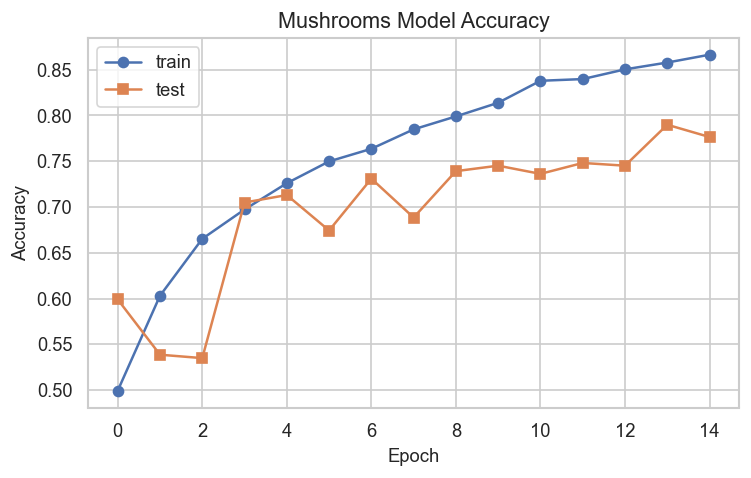

In [10]:
def print_history(train_hist, test_hist, title):
    plt.figure(figsize=(7, 4))
    plt.plot(train_hist, label='train', marker='o')
    plt.plot(test_hist, label='test', marker='s')
    plt.title(title)
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend()
    plt.grid(True)
    plt.show()

print_history(train_hist, test_hist, "Mushrooms Model Accuracy")

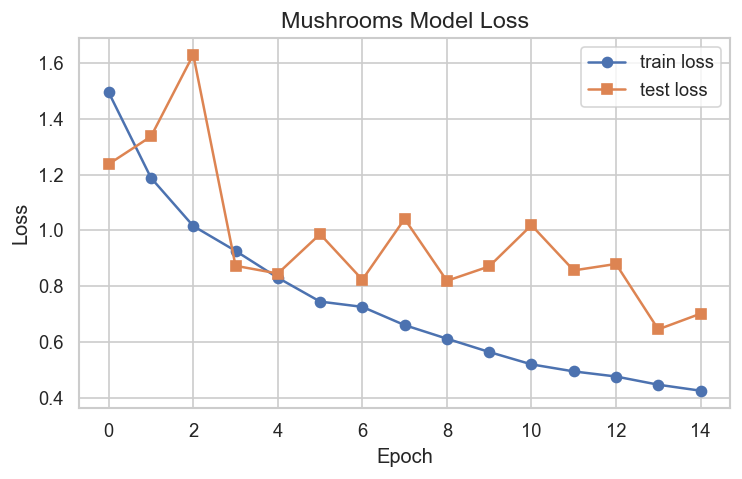

In [11]:
def print_loss_history(train_loss, val_loss, title):
    plt.figure(figsize=(7, 4))
    plt.plot(train_loss, label='train loss', marker = 'o')
    plt.plot(val_loss, label='test loss', marker = 's')
    plt.title(title, fontsize=14)
    plt.ylabel('Loss', fontsize=12)
    plt.xlabel('Epoch', fontsize=12)
    plt.legend()
    plt.grid(True)
    plt.show()


    """plt.legend(fontsize=11)
    plt.grid(True, alpha=0.6)
    plt.xticks(np.arange(0, len(train_loss), 1))
    plt.tight_layout()
    plt.show()"""

print_loss_history(train_loss_hist, val_loss_hist, "Mushrooms Model Loss")

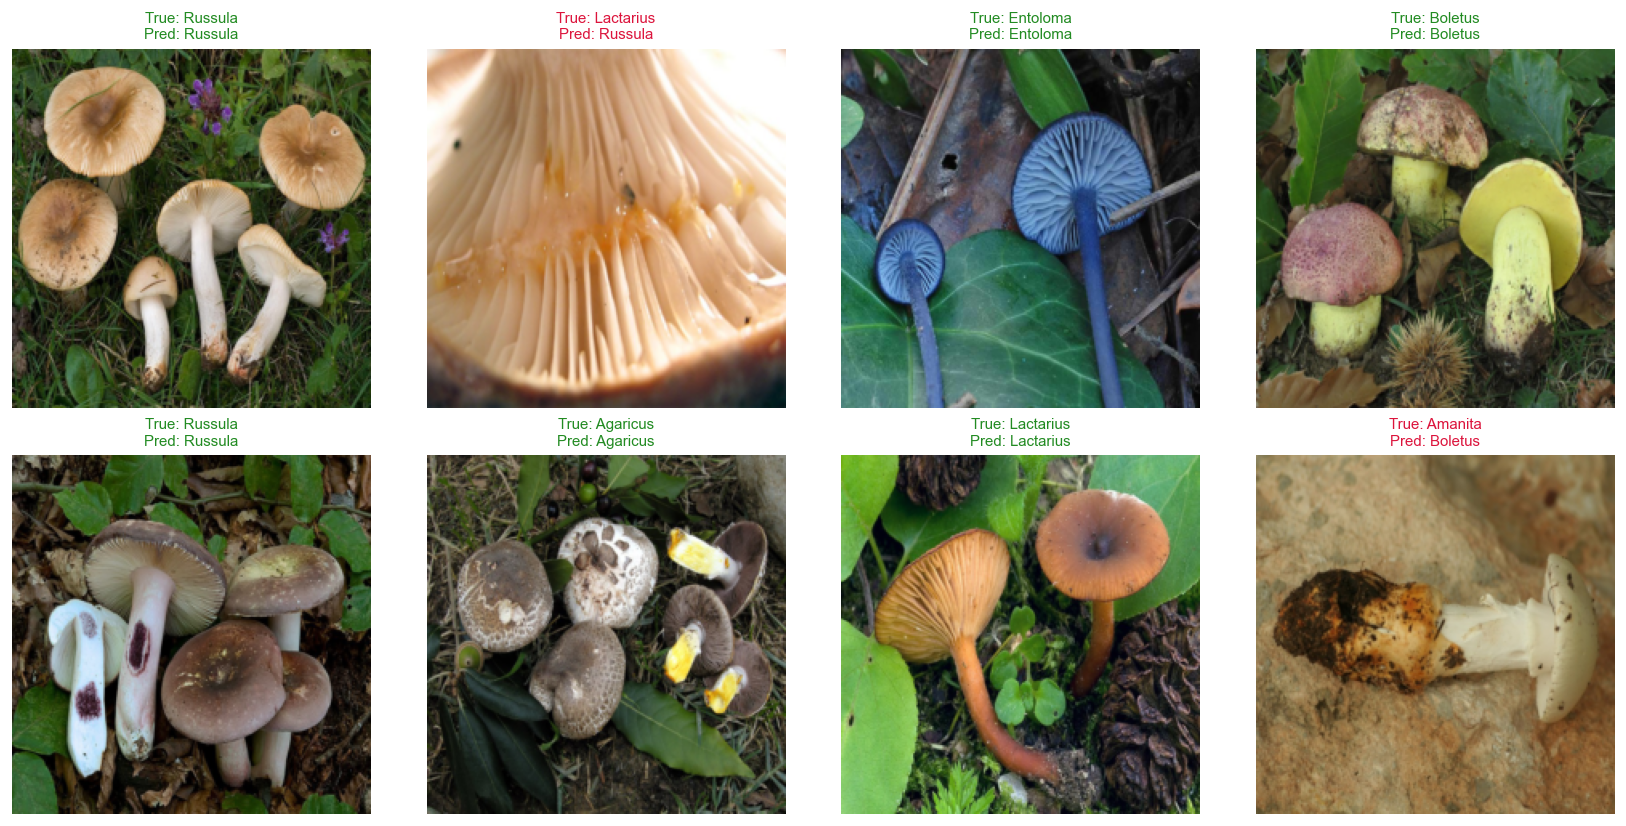

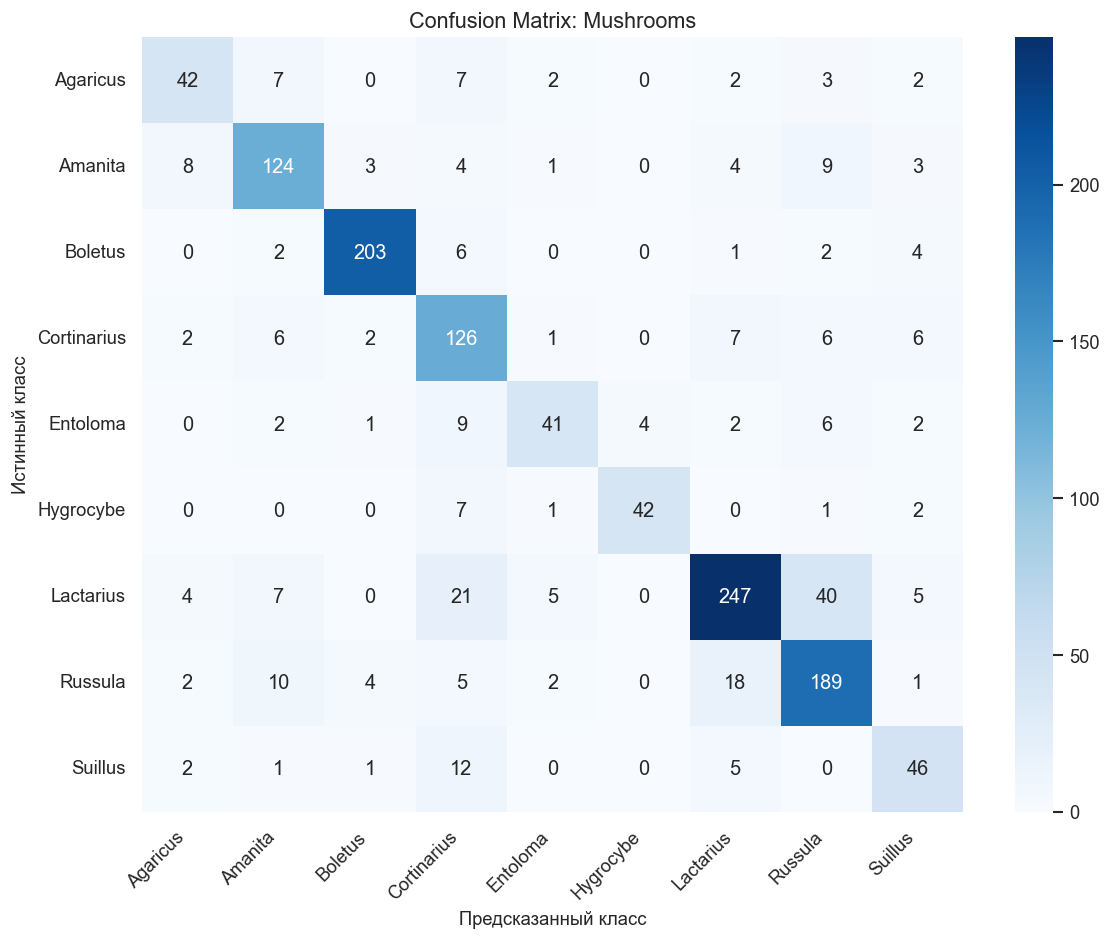

In [16]:
def show_predictions(net, dataloader, n=8):
    net.eval()
    images_data, original_label = next(iter(dataloader))
    images_data = images_data[:n]
    original_label = original_label[:n]

    with torch.no_grad():
        outputs = net(images_data.to(device))
        _, predicted = outputs.max(1)

    mean = torch.tensor(Image_Net_Mean).view(3, 1, 1)
    std = torch.tensor(Image_Net_Std).view(3, 1, 1)

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for i, ax in enumerate(axes.flat):
        if i >= len(images_data):
            ax.axis("off")
            continue

        
        img = (images_data[i].cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
        ax.imshow(img)

        is_correct = (original_label[i] == predicted[i].cpu())
        c = 'forestgreen' if is_correct else 'crimson'

        ax.set_title(f"True: {class_names[original_label[i]]}\nPred: {class_names[predicted[i]]}", 
                     color=c, fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_predictions(net, test_dataloader)


net.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in test_dataloader:
        outputs = net(inputs.to(device))
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set(xlabel="Предсказанный класс", ylabel="Истинный класс", title="Confusion Matrix: Mushrooms")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Вывод**
=================
**Результаты и анализ графиков**
_________________________
По итогам обучения лучшая точность на тестовой выборке составила ~79%.

Анализ графиков:
_______________

* График Accuracy (Точность): Синяя линия (train) плавно растет до 86%, оранжевая (test) достигает 79%. Небольшой разрыв и отсутствие роста тестовой ошибки при падении тренировочной свидетельствуют об отсутствии переобучения. Колебания тестовой точности объясняются малым размером валидационной выборки (20% датасета).  

![Mushroom Model Accuracy.png](<attachment:Mushroom Model Accuracy.png>)

* График Loss (Ошибка): Обе линии снижаются. Train loss падает с 1.5 до 0.4. Test loss также имеет тренд на снижение, что подтверждает адекватность обучения.  

![Mushroom Model Loss.png](<attachment:Mushroom Model Loss.png>)  

* Визуализация предсказаний и матрица ошибок  
Матрица ошибок (Confusion Matrix) показала, что большинство классов классифицируются верно (высокие значения по диагонали). Основные ошибки возникают между визуально похожими видами (например, некоторые виды пластинчатых грибов путаются между собой).  

Визуализация предсказаний на тестовых картинках показала, что модель уверенно определяет характерные признаки (цвет шляпки, форму ножки) и в большинстве случаев дает верные ответы.  

![Mushroom True_Pred.png](<attachment:Mushroom True_Pred.png>)  

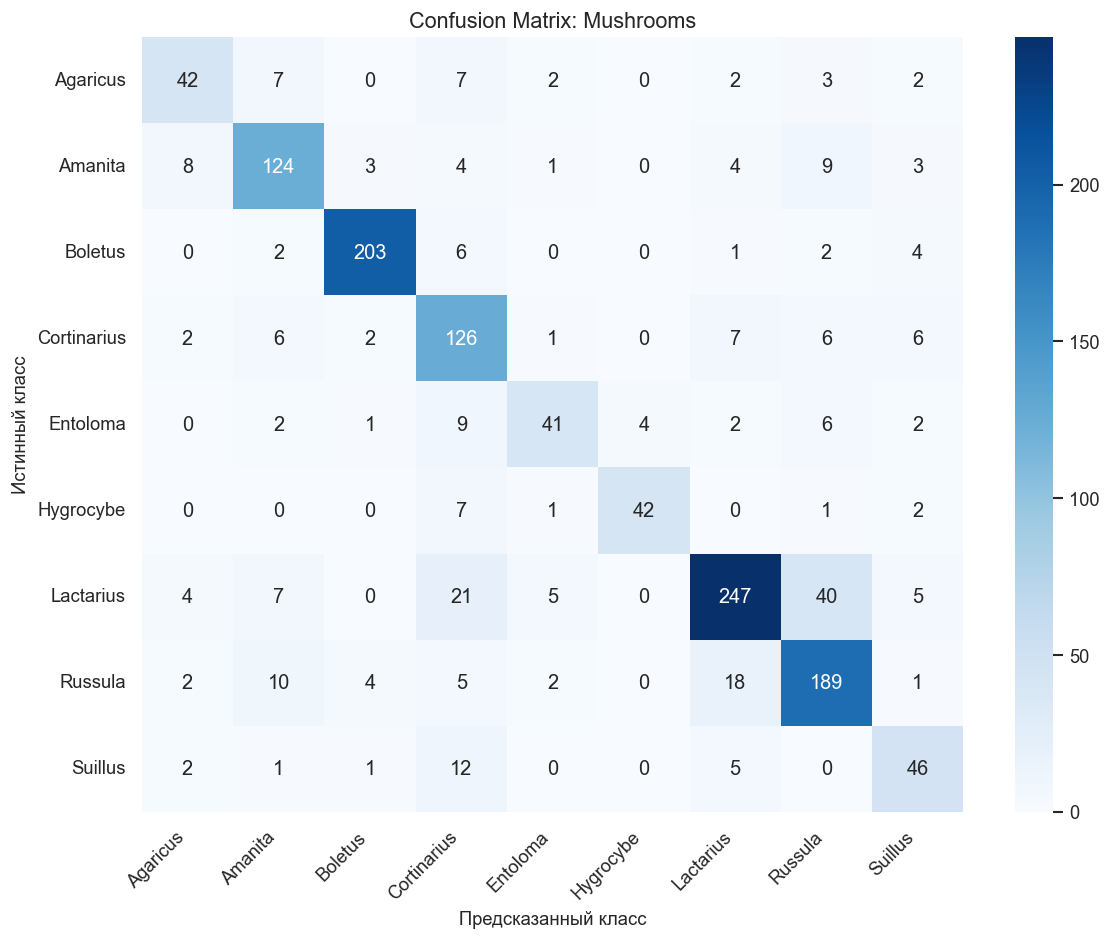
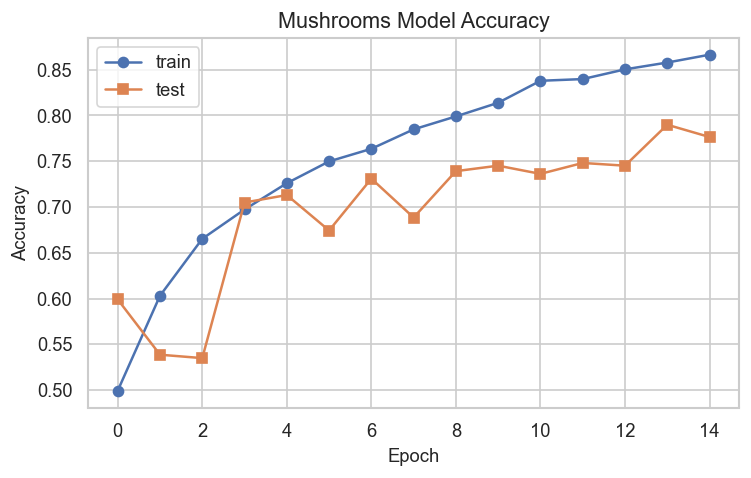
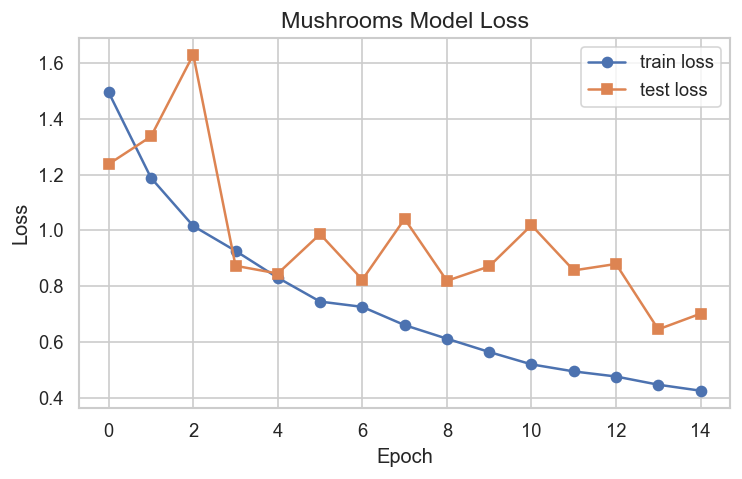
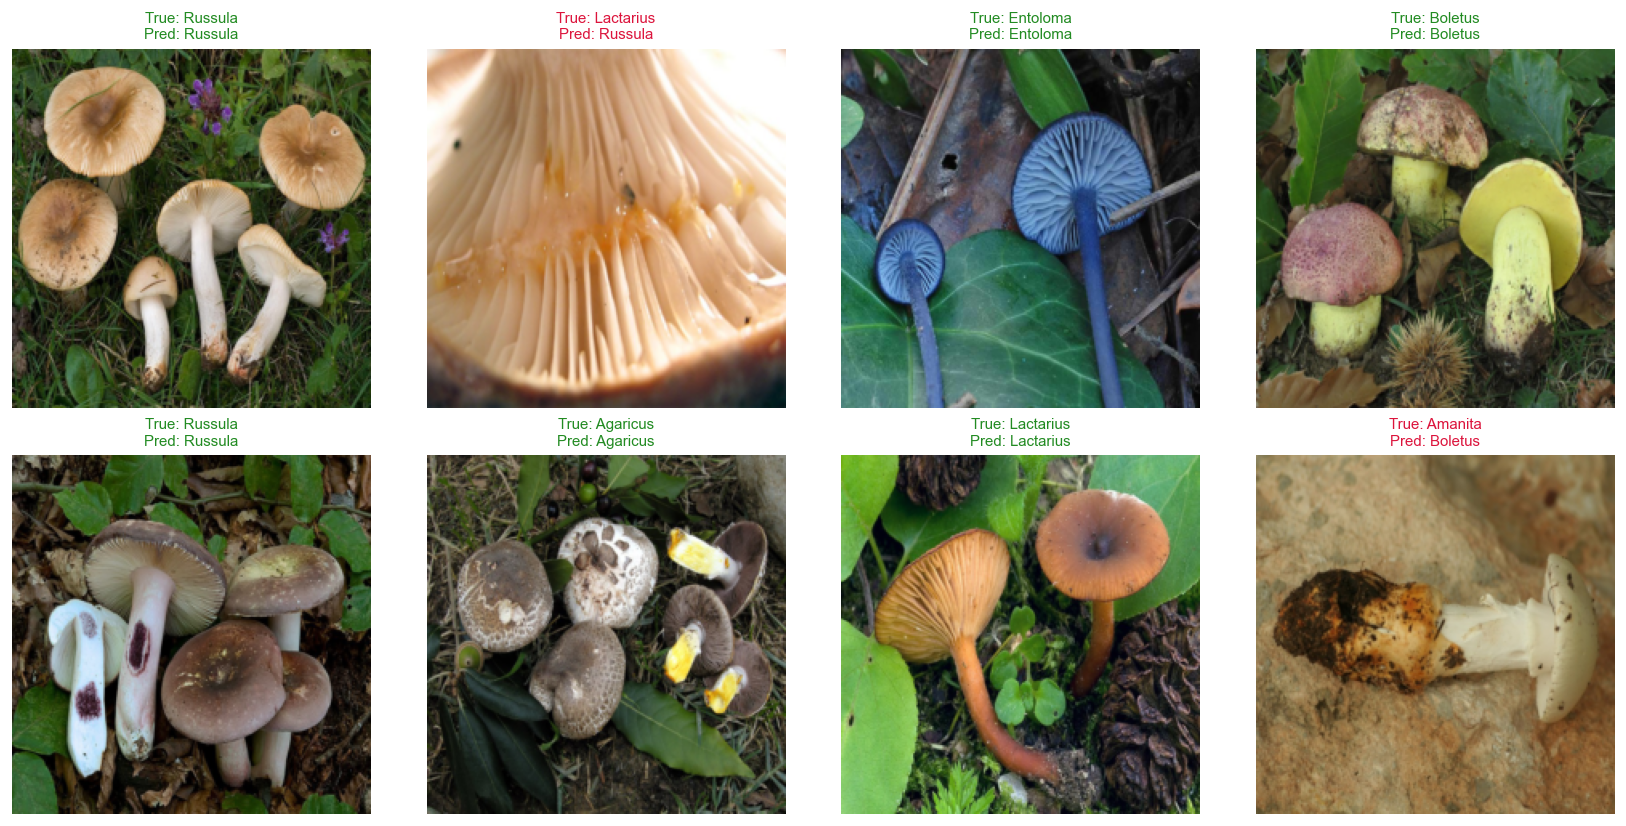